In [380]:
!pip install numpy matplotlib yfinance scipy pandas seaborn

import numpy as np
import yfinance
#import seaborn
import pandas as pd
import scipy
from matplotlib import pyplot as plt

#sns.set()
plt.style.use('ggplot')

In [121]:
data = yfinance.download("AMZN", start="2025-01-01", end="2026-01-01")
close = data["Close"]

[*********************100%***********************]  1 of 1 completed


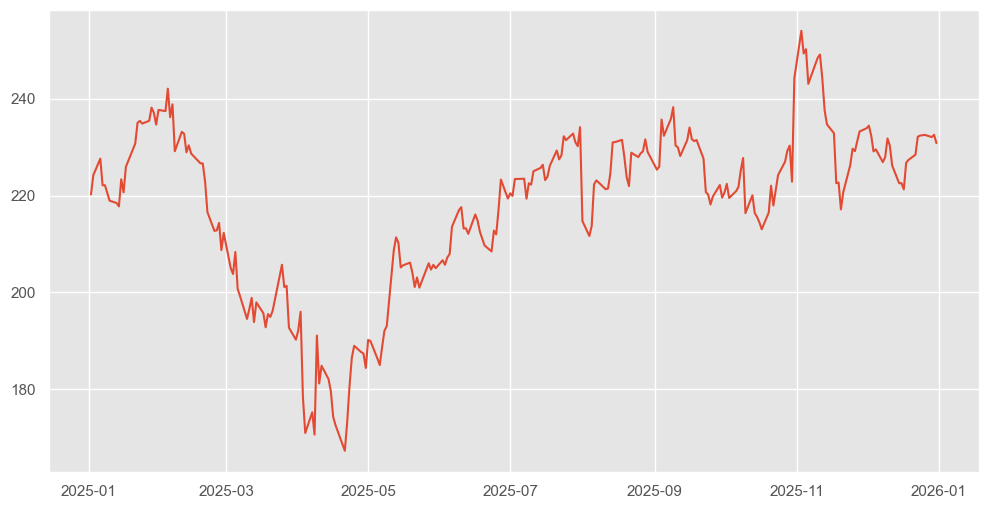

In [402]:
plt.figure(figsize=(12, 6))
plt.plot(close)
plt.show()

In [135]:
log_returns = np.log(close/close.shift(1)).iloc[1:]
mu = log_returns.mean().values
sigma = log_returns.std().values

print(f"Daily standard deviation of log returns: {round(sigma[0], 6)} ({round(sigma[0]*100, 1)}%)")

Daily standard deviation of log returns: 0.021627 (2.2%)


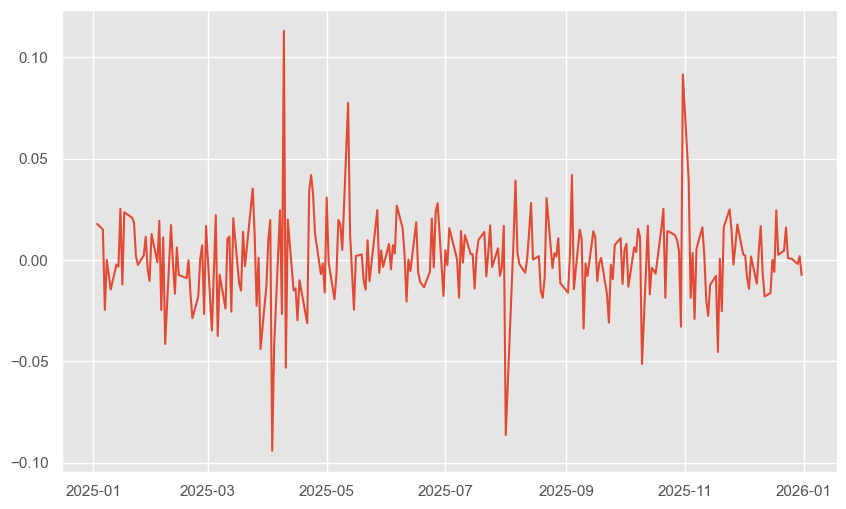

In [403]:
plt.figure(figsize=(10, 6))
plt.plot(log_returns)
plt.show()

In [413]:
T = 252
N = 100 # Just to visualization purpose
r = 0.05/T # 5% annually
K = 240

In [399]:
def MC_simulation(T, N, mu, sigma, close):
    dt = 1
    Z = np.random.standard_normal(size=(T, N))
    returns = np.exp((mu - 0.5*sigma**2)*dt + sigma*np.sqrt(dt)*Z)
    
    S0 = close.iloc[-1].values[0]
    paths = S0*np.cumprod(returns, axis=0)

    return paths

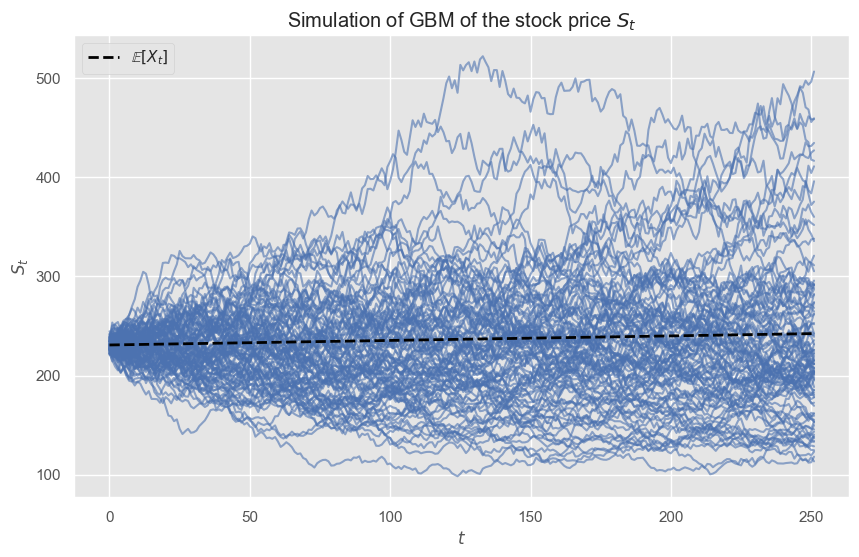

In [414]:
paths = MC_simulation(T, N, r, sigma, close) 


S0 = close.iloc[-1].values[0]
t = np.arange(paths.shape[0])
linear_drift = S0 * (1 + r * t)

plt.figure(figsize=(10, 6))
plt.title("Simulation of GBM of the stock price $S_t$")
plt.plot(paths, color="b", alpha=0.6)
plt.plot(t, linear_drift, linestyle="--", c="black", linewidth=2, label="$\mathbb{E}[X_t]$")
plt.xlabel("$t$")
plt.ylabel("$S_t$")
plt.legend()
plt.show()

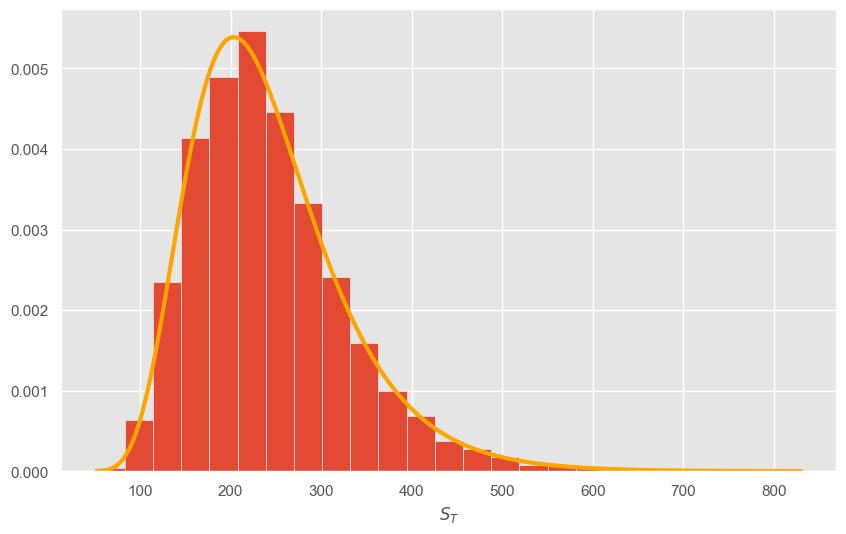

In [401]:
 
paths = MC_simulation(T, 10_000, r, sigma, close) # New paths 

S0 = close.iloc[-1].values[0]
dist = scipy.stats.lognorm(
    s=sigma * np.sqrt(T),
    scale=S0 * np.exp((r - 0.5 * sigma**2) * T)
)

x = np.linspace(np.min(paths[-1, :]), np.max(paths[-1, :]), 1000)

plt.figure(figsize=(10, 6))
plt.hist(paths[-1, :], bins=25, density=True)
plt.plot(x, dist.pdf(x), color="orange", lw=3)
plt.xlabel("$S_T$")
plt.show()

## European Option Pricing with Black-Scholes

In [291]:
def monte_carlo_pricing(S0, N, r, sigma, T, K, close):
    Z = np.random.standard_normal(N)
    ST = S0 * np.exp((r - 0.5 * sigma**2) * T + sigma * np.sqrt(T) * Z)
    
    payoff = np.maximum(ST - K, 0)
    price = np.exp(-r*T) * np.mean(payoff)

    return price, payoff

MC price of the European Call Option: 32.3203
 


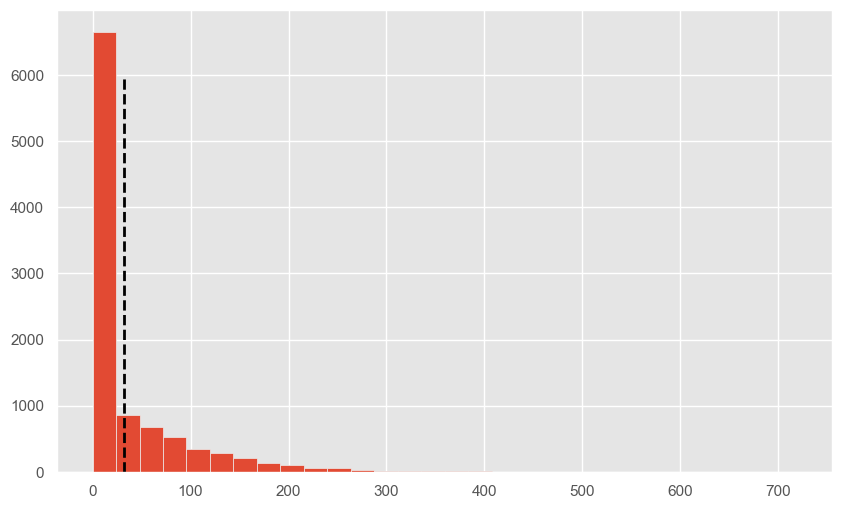

In [393]:
S0 = close.iloc[-1].values[0]
price, payoff = monte_carlo_pricing(S0, 10_000, r, sigma, T, K, close)

print(f"MC price of the European Call Option: {round(price, 4)}")
print(" ")

plt.figure(figsize=(10, 6))
plt.hist(payoff, bins=30)
plt.plot(price*np.ones(1_000), np.linspace(0, 6000, 1000), linestyle="--", color="black", lw=2)
plt.show()

In [296]:
# We implement black scholes formula for european option to compare the value with the mc method
from scipy.stats import norm

def bs_european_call(S0, K, r, T, sigma):
    d1 = (np.log(S0/K) + (r + 0.5*sigma**2)*T) / (sigma*np.sqrt(T))
    d2 = d1 - sigma*np.sqrt(T)
    
    C = S0*norm.cdf(d1) - K*np.exp(-r*T)*norm.cdf(d2)
    return C

bs_price = bs_european_call(S0, K, r, T, sigma)[0]
print(f"Call option price by Black-Scholes formula: {round(bs_price, 4)}")

Call option price by Black-Scholes formula: 32.5656


In [297]:
Nvalues = [250, 1000, 10_000, 100_000, 1_000_000]

for N in Nvalues:
    price, payoff = monte_carlo_pricing(S0, N, r, sigma, T, K, close)
    print(f"Iterations: {N:<7} | MC price: {round(price, 4):<7} | Error {round(price-bs_price, 4):<7} | Error (%): {abs(round((price-bs_price)/bs_price, 3))}")

Iterations: 250     | MC price: 34.6677 | Error 2.1021  | Error (%): 0.065
Iterations: 1000    | MC price: 32.7505 | Error 0.1849  | Error (%): 0.006
Iterations: 10000   | MC price: 32.1865 | Error -0.3791 | Error (%): 0.012
Iterations: 100000  | MC price: 32.7595 | Error 0.1939  | Error (%): 0.006
Iterations: 1000000 | MC price: 32.5629 | Error -0.0027 | Error (%): 0.0


## Volatility Smile

In [304]:
ticker = yfinance.Ticker("AMZN")
expiry = ticker.options[2]
calls = ticker.option_chain(expiry).calls.copy()

S0 = float(ticker.history(period="1d")["Close"].iloc[-1])
calls["mid"] = (calls["ask"] + calls["bid"]) / 2
time = (pd.Timestamp(expiry).date() - pd.Timestamp.now().date()).days / 365
r = 0.0439

calls.head()

,contractSymbol,lastTradeDate,strike,lastPrice,bid,ask,change,percentChange,volume,openInterest,impliedVolatility,inTheMoney,contractSize,currency,mid
0,AMZN261111C00190000,2026-10-30 15:22:58+00:00,190.0,51.59,68.85,71.40,0.0,0.0,2.0,1,1.457522,True,REGULAR,USD,70.125
1,AMZN261111C00197500,2026-10-30 14:19:10+00:00,197.5,39.05,60.95,64.40,0.0,0.0,4.0,2,1.321292,True,REGULAR,USD,62.675
2,AMZN261111C00200000,2026-10-30 13:41:17+00:00,200.0,37.75,58.85,61.40,0.0,0.0,3.0,5,1.255863,True,REGULAR,USD,60.125
3,AMZN261111C00205000,2026-10-29 15:30:07+00:00,205.0,44.30,53.45,56.40,0.0,0.0,NaN,15,1.093266,True,REGULAR,USD,54.925
4,AMZN261111C00215000,2026-11-05 16:02:09+00:00,215.0,40.25,43.55,46.45,0.0,0.0,1.0,18,0.930176,True,REGULAR,USD,45.000


In [305]:
from scipy.optimize import brentq

IV_list = []
for strike, C_market in zip(calls["strike"], calls["mid"]):
    IV = brentq(lambda sigma: bs_european_call(S0, strike, r, time, sigma) - C_market, 1e-6, 5)
    IV_list.append(IV)

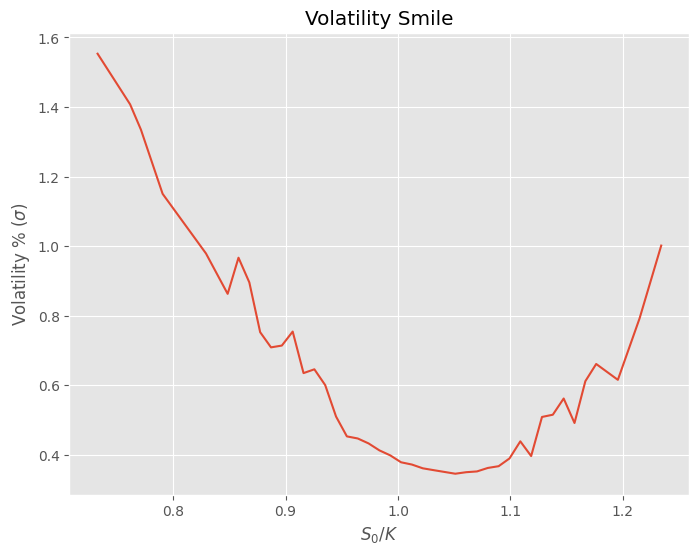

In [377]:
plt.figure(figsize=(8, 6))
plt.title("Volatility Smile")
plt.plot(calls["strike"]/S0, IV_list)
plt.xlabel("$S_0/K$")
plt.ylabel("Volatility % $(\sigma)$")
plt.show()

## American Options: Longstaff–Schwartz Algorithm

In [301]:
def exercise(X, K):
    return np.maximum(K - X, 0)

In [383]:
N = 60
paths = MC_simulation(T, N, r, sigma, close)  # Small number again only for visualization purpose

X = paths[-1,:]
Y = exercise(X, K)
xplot = np.linspace(np.min(X), np.max(X), N)

p4 = np.polynomial.Chebyshev.fit(X, Y, 4)
p6 = np.polynomial.Chebyshev.fit(X, Y, 6)

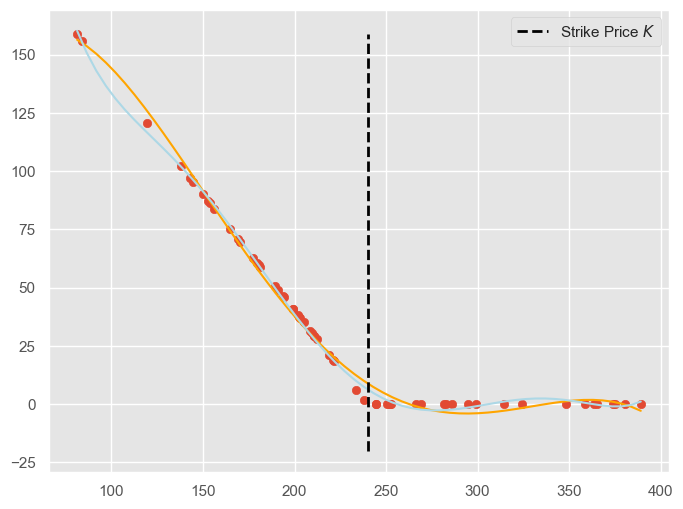

In [389]:
plt.figure(figsize=(8, 6))
plt.scatter(X, Y)
plt.plot(xplot, p4(xplot), c="orange", label)
plt.plot(xplot, p6(xplot), c="lightblue")
plt.plot(K*np.ones(100), np.linspace(-20, np.max(Y), 100), c="black", linestyle="--", lw=2, label="Strike Price $K$")
plt.legend()
plt.show()

In [355]:
def longstaff_schwartz(paths, K, N, T, deg=4):
    dt = 1    
    Chat_list = [] # Remember to reverse it
    tau = np.full(N, T-1, dtype=int)
    for t in range(T-2, 0, -1):
        
        X = paths[t,:]
        V = np.exp(-r*(tau-t)*dt)*exercise(paths[tau, np.arange(N)], K)
    
        itm = X < K
        if itm.sum() > deg+1: # Check that it has enough ITM trajectories to have a good fit
            C_hat = np.polynomial.Chebyshev.fit(X[itm], V[itm], deg) # We want to fit only the ITM part
            tau[itm & (C_hat(X) < K - X)] = t
            Chat_list.append(C_hat)
        else:
            Chat_list.append(None)

    return tau, Chat_list

In [370]:
tau, Chat_list = longstaff_schwartz(paths, K, N, T)

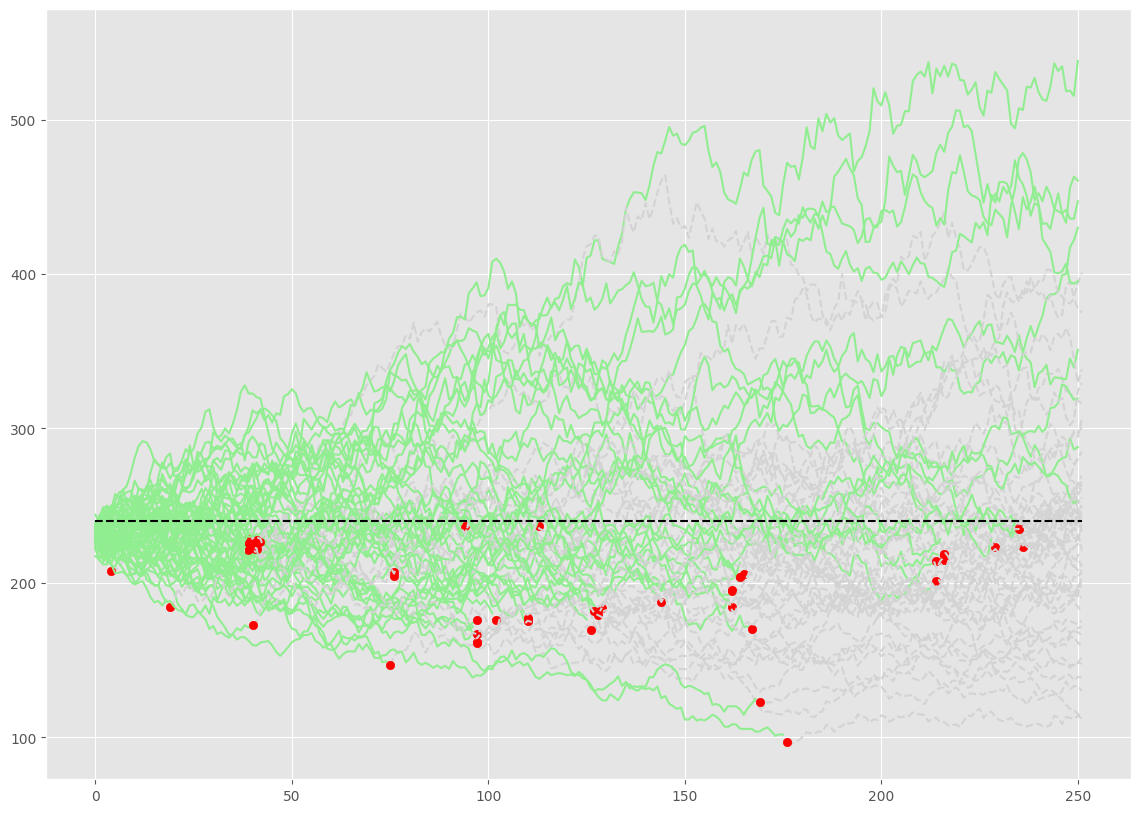

In [371]:
plt.figure(figsize=(14, 10))

for idx in range(paths.shape[1]):
    exercise_time = tau[idx]
    path = paths[:,idx]
    plt.plot(range(exercise_time, T), path[exercise_time:], c="lightgrey", linestyle="--")
    plt.plot(range(exercise_time), path[:exercise_time], c="lightgreen")
    
    if path[exercise_time] < K:
        plt.scatter(exercise_time, path[exercise_time], c="red", zorder=2)

plt.plot(np.arange(T), K*np.ones(T), linestyle="--", c="black")
plt.show()

In [411]:
N = 10_000
paths = MC_simulation(T, N, r, sigma, close)
tau, Chat_list = longstaff_schwartz(paths, K, N, T, deg=6)

european = np.exp(-r*T)*np.mean(np.maximum(K - paths[-1,:], 0))
american = 1/N * np.sum(np.exp(-r*(tau+1)*dt)*np.maximum(K - paths[tau, np.arange(N)], 0))

print(f"European put option price using MC: {round(european, 4)}")
print(f"American put option price using Longstaff–Schwartz: {round(american, 4)}")

European put option price using MC: 30.1066
American put option price using Longstaff–Schwartz: 31.5635


In [387]:
EEP = american - european
print(f"Early Exercise Premium: {np.round(EEP, 4)}")

Early Exercise Premium: 1.7882
